# ✋ See, Detect, Understand: Build a Hand Gesture Recogniser

## INSTRUCTOR TEMPLATE

> **What you are going to do:** You will use MediaPipe to locate hand landmarks, convert those landmarks into numerical features, and train a small classifier to recognise four hand gestures.

Earlier, we used a pretrained CNN (MobileNetV2) to classify images.

We then explored how Computer Vision can go beyond classification,
using object detection, segmentation and keypoint detection.

Now, let's bring these ideas together!

**Our challenge:**

> Can we build a system that recognises hand gestures from images it has never seen before?

### Learning goals

By the end of this hands-on, you should be able to:

- Explain how a hand image can be represented by 21 landmarks.
- Create wrist-relative features from landmark coordinates.
- Train and evaluate a gesture classifier using labelled examples.
- Explain why testing on a person not used for training is important.
- Run the complete computer vision pipeline on an unseen hand image.

### Workshop route

| Section | Activity | Suggested use |
| --- | --- | --- |
| 0. Setup | Load libraries and the MediaPipe model | Provided code |
| 1. Pipeline | Understand the recognition task and gesture labels | Discussion |
| 2. Landmarks | Detect and visualise a hand's 21 landmarks | Explore |
| 3. Features | Build wrist-relative landmark features | Exercise 1 |
| 4. Dataset | Prepare participant-separated training and test data | Provided code |
| 5. Classifier | Train a Random Forest gesture classifier | Exercise 2 |
| 6. Evaluation | Inspect accuracy and the confusion matrix | Investigate |
| 7. Full pipeline | Predict a gesture for a new hand image | Exercise 3 |

## 0. Setup

Run the following cells to set up the environment. You do not need to modify the code in this section.

### 0.1 Install dependencies

In [1]:
# Install the packages this notebook needs into the kernel you selected.
%pip install -q -r requirements.txt


Note: you may need to restart the kernel to use updated packages.


### 0.2 Import Libraries

In [35]:
import os
import logging
import warnings

# Reduce TensorFlow / MediaPipe logging
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["GLOG_minloglevel"] = "3"
os.environ["ABSL_MIN_LOG_LEVEL"] = "3"

# Suppress Python warnings
warnings.filterwarnings("ignore")

# Reduce Python logging
logging.getLogger("mediapipe").setLevel(logging.ERROR)
logging.getLogger("absl").setLevel(logging.ERROR)

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, 
    ConfusionMatrixDisplay
)
from pathlib import Path
from urllib.request import urlretrieve

import mediapipe as mp
import mediapipe.tasks as tasks
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from sklearn.model_selection import train_test_split

import time

print("MediaPipe version:", mp.__version__)
print("Setup successful!")

MediaPipe version: 0.10.14
Setup successful!


### 0.3 Download MediaPipe model

This is a pretrained MediaPipe Hand Landmarker model itself.

In [4]:
MODEL_PATH = Path("hand_landmarker.task")

MODEL_URL = (
    "https://storage.googleapis.com/mediapipe-models/"
    "hand_landmarker/hand_landmarker/float16/1/"
    "hand_landmarker.task"
)

if not MODEL_PATH.exists():
    print("Downloading MediaPipe Hand Landmarker model...")
    urlretrieve(MODEL_URL, MODEL_PATH)

print("Model ready:", MODEL_PATH.exists())

Model ready: True


### 0.4 Initialise the Hand Landmarker

In [11]:
base_options = python.BaseOptions(
    model_asset_path=str(MODEL_PATH)
)

options = vision.HandLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.IMAGE,
    num_hands=1
)

landmarker = vision.HandLandmarker.create_from_options(options)

print("Hand Landmarker initialised!")

Hand Landmarker initialised!


## 1. What Are We Building? ✋

We have seen how Computer Vision uses **keypoints and landmarks** to identify important structures in images.

Now, we will use these landmarks to build our own **hand gesture recogniser**.

> **Can we train a model to recognise hand gestures and use it for live webcam predictions?**

### 1.1 Our Computer Vision Pipeline

Our system consists of two components:

**Part A: Pretrained Computer Vision**

Hand Image → MediaPipe → 21 Hand Landmarks

MediaPipe detects 21 hand landmarks, including fingertips and joints, without requiring us to train the detector.

**Part B: Our Gesture Recogniser**

21 Landmarks → Numerical Features → Gesture Classifier → Prediction

We will convert the landmarks into numerical features and train our own classifier.

**Compared to our earlier MobileNetV2 example:**
- Earlier: We used a pretrained model to classify images.
- Now: We use a pretrained landmark detector and train our own classifier.

### 1.2 Your Task

During this hands-on, you will:

1. **Explore:** Visualise MediaPipe's 21 hand landmarks.
2. **Extract:** Convert hand images into numerical landmark features.
3. **Train and evaluate:** Build a gesture classifier using the extracted features.
4. **Apply:** Test your trained model using a live webcam.

### 1.3 Our Dataset

We will use a subset of the **HaGRID hand gesture dataset**, containing 400 images across four classes.

| Gesture | Label | Images |
|---|---|---|
| ✊ Fist | `fist` | 100 |
| 👍 Thumbs Up | `like` | 100 |
| ✋ Open Palm | `palm` | 100 |
| ✌️ Peace | `peace` | 100 |

We will use MediaPipe to extract **21 landmarks × 3 coordinates (x, y, z) = 63 numerical features** from each detected hand.

These features will be used to train our gesture classifier, which we will later test on unseen images and live webcam input.

## 2. Explore Hand Landmarks

MediaPipe detects **21 hand landmarks**, each represented by `(x, y, z)` coordinates.

Let's visualise these landmarks on an image from our HaGRID dataset.

### 2.1 Load a Hand Image

We will start with an open palm image.

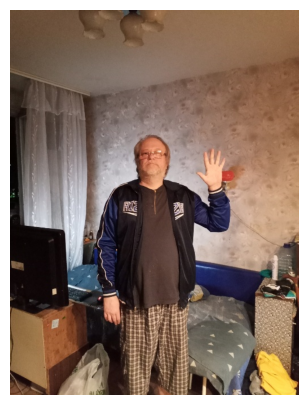

In [12]:
IMAGE_PATH = sorted((Path("data/hagrid/palm")).glob("*.jpg"))[0]

image = cv2.imread(str(IMAGE_PATH))
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(5, 5))
plt.imshow(image_rgb)
plt.axis("off")
plt.show()

### 2.2 Detect Hand Landmarks

Use the pretrained MediaPipe Hand Landmarker to identify the hand's structure.

In [13]:
mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=image_rgb
)

result = landmarker.detect(mp_image)

if not result.hand_landmarks:
    raise ValueError("No hand detected. Try another image.")

hand_landmarks = result.hand_landmarks[0]

print("Hands detected:", len(result.hand_landmarks))
print("Landmarks detected:", len(hand_landmarks))

Hands detected: 1
Landmarks detected: 21


### 2.3 Visualise the 21 Landmarks

Let's draw the detected landmarks and connections to see how MediaPipe represents the hand.

In [14]:
HAND_CONNECTIONS = [
    (0, 1), (1, 2), (2, 3), (3, 4),
    (0, 5), (5, 6), (6, 7), (7, 8),
    (5, 9), (9, 10), (10, 11), (11, 12),
    (9, 13), (13, 14), (14, 15), (15, 16),
    (13, 17), (17, 18), (18, 19), (19, 20),
    (0, 17)
]

def draw_hand_landmarks(image, landmarks):
    output = image.copy()
    h, w = output.shape[:2]

    points = [
        (int(lm.x * w), int(lm.y * h))
        for lm in landmarks
    ]

    for start, end in HAND_CONNECTIONS:
        cv2.line(output, points[start], points[end], (255, 255, 255), 2)

    for i, point in enumerate(points):
        cv2.circle(output, point, 5, (0, 255, 0), -1)
        cv2.putText(
            output, str(i), (point[0] + 5, point[1] - 5),
            cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 0), 1
        )

    return output

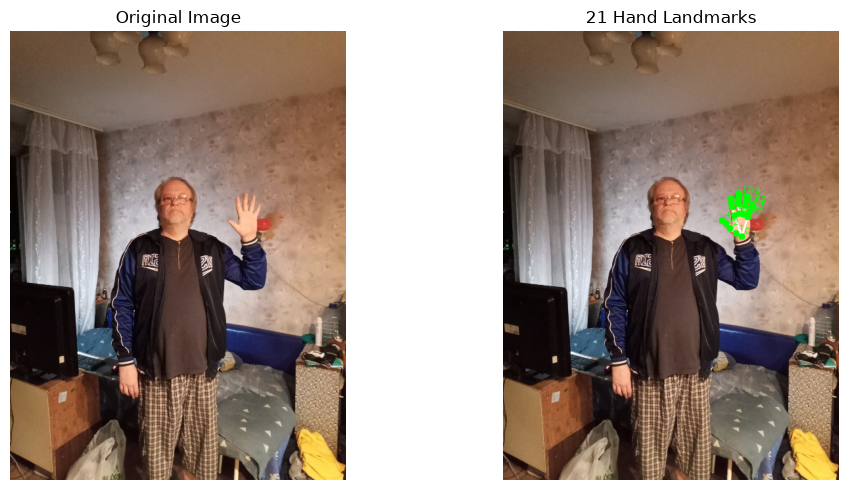

In [20]:
landmark_image = draw_hand_landmarks(image_rgb, hand_landmarks)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].imshow(image_rgb)
axes[0].set_title("Original Image")

axes[1].imshow(landmark_image)
axes[1].set_title("21 Hand Landmarks")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Zoom Into the Detected Hand

We can use the landmark coordinates to calculate a **bounding box** around the hand.

Let's draw the bounding box and crop the image to get a closer look at the landmarks.

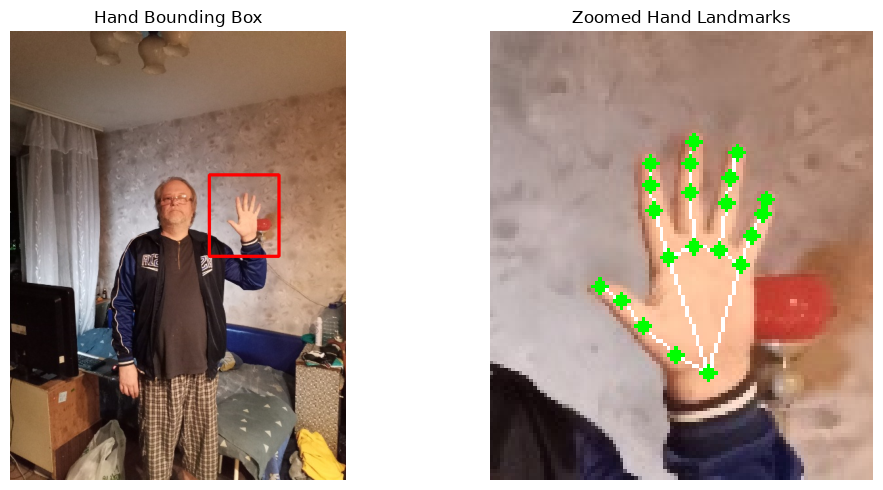

In [21]:
# Convert landmarks to pixel coordinates
h, w = image_rgb.shape[:2]

points = np.array([
    [int(lm.x * w), int(lm.y * h)]
    for lm in hand_landmarks
])

# Calculate bounding box with padding
padding = 30

x_min = max(0, points[:, 0].min() - padding)
y_min = max(0, points[:, 1].min() - padding)
x_max = min(w, points[:, 0].max() + padding)
y_max = min(h, points[:, 1].max() + padding)

# Draw bounding box on original image
boxed_image = image_rgb.copy()

cv2.rectangle(
    boxed_image,
    (x_min, y_min),
    (x_max, y_max),
    (255, 0, 0),
    3
)

# Crop the original image (without annotations)
cropped_hand = image_rgb[y_min:y_max, x_min:x_max].copy()

# Adjust landmark coordinates relative to the crop
crop_points = points - [x_min, y_min]

# Draw connections
for start, end in HAND_CONNECTIONS:
    cv2.line(
        cropped_hand,
        tuple(crop_points[start]),
        tuple(crop_points[end]),
        (255, 255, 255),
        1
    )

# Draw smaller landmarks without numbers
for point in crop_points:
    cv2.circle(
        cropped_hand,
        tuple(point),
        2,
        (0, 255, 0),
        -1
    )

# Visualise
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].imshow(boxed_image)
axes[0].set_title("Hand Bounding Box")

axes[1].imshow(cropped_hand)
axes[1].set_title("Zoomed Hand Landmarks")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

**Observe:**

- The bounding box is calculated from the detected hand landmarks.
- Cropping allows us to inspect the hand structure more closely.
- MediaPipe identifies the hand's structure, but does not directly classify the gesture.

Next, let's explore the numerical coordinates behind these landmarks.

### 2.4 Understand the Landmark Coordinates

Each landmark represents a specific part of the hand.

| Landmark | Hand Part |
|---|---|
| `0` | Wrist |
| `4` | Thumb tip |
| `8` | Index fingertip |
| `12` | Middle fingertip |
| `16` | Ring fingertip |
| `20` | Pinky fingertip |

Each landmark contains three coordinates:

- **x:** Horizontal position (normalised by image width).
- **y:** Vertical position (normalised by image height).
- **z:** Relative depth, with the wrist as the origin.

Let's inspect the coordinates of the index fingertip (`landmark 8`).

In [22]:
index_tip = hand_landmarks[8]

print("Index fingertip (Landmark 8)")
print(f"x = {index_tip.x:.3f}")
print(f"y = {index_tip.y:.3f}")
print(f"z = {index_tip.z:.3f}")

Index fingertip (Landmark 8)
x = 0.678
y = 0.372
z = -0.029


In [24]:
# Raw wrist coordinates from MediaPipe
wrist = hand_landmarks[0]

print("Raw wrist coordinates:")
print(f"x = {wrist.x:.3f}")
print(f"y = {wrist.y:.3f}")
print(f"z = {wrist.z:.3f}")

Raw wrist coordinates:
x = 0.709
y = 0.457
z = 0.000


### 2.5 Quick Practice ✍️

Landmark `12` represents the **middle fingertip**.

Complete the code to display its `(x, y, z)` coordinates.

In [23]:
# middle_tip = hand_landmarks[__]
middle_tip = hand_landmarks[12]

print(f"x = {middle_tip.x:.3f}")
print(f"y = {middle_tip.y:.3f}")
print(f"z = {middle_tip.z:.3f}")

x = 0.701
y = 0.364
z = -0.023


We have converted a hand image into **21 landmarks × 3 coordinates = 63 numerical values**.

However, the same gesture can appear at different positions and sizes.

**How can we make our features less sensitive to these differences?**

Next, we'll create wrist-relative, normalised features for our classifier.

### 2.6 From Landmarks to Features

MediaPipe gives us **21 landmarks**, each with `(x, y, z)` coordinates.

This produces:
$21 \times 3 = 63 \text{ numerical values}$

However, the same gesture may appear at different positions and sizes in an image.

**Question:** How can we represent the hand so that our classifier focuses on its shape rather than its position?

In the next section, we will create **wrist-relative, scale-normalised features** to make our representation less sensitive to these differences.

## 3. From Landmarks to Gesture Features

We now have 21 hand landmarks, each containing `(x, y, z)` coordinates.

This gives us **21 × 3 = 63 numerical values**.

But are raw landmark coordinates the best representation for recognising gestures?

### 3.1 A Problem With Raw Coordinates

Imagine showing the same ✌️ gesture at two different positions in an image.

Although the gesture remains the same, its landmark coordinates change.

**Our challenge:** How can we represent the hand's structure while reducing the influence of its position?

In [25]:
# Simulate moving the same hand horizontally
original_x = hand_landmarks[8].x
shifted_x = original_x + 0.2

print(f"Original index fingertip x: {original_x:.3f}")
print(f"Shifted index fingertip x:  {shifted_x:.3f}")

Original index fingertip x: 0.678
Shifted index fingertip x:  0.878


*For demonstration only.*

The fingertip's position changed, but the gesture did not.

Instead of using absolute positions, let's represent landmarks relative to the wrist.

### 3.2 Use the Wrist as Our Reference Point

We can reduce the effect of hand position by subtracting the **wrist coordinates (landmark 0)** from every landmark.
$P_{\text{relative}} = P_{\text{landmark}} - P_{\text{wrist}}
$
This makes the wrist `(0, 0, 0)` while preserving the relative positions of the fingers and joints.

### 💻 Exercise 1: Calculate Wrist-Relative Coordinates

Calculate the wrist-relative `(x, y, z)` coordinates of the **index fingertip (landmark 8)**.

**Hint:** Subtract the wrist coordinates from the fingertip coordinates.

In [30]:
wrist = hand_landmarks[0]

# relative_x = __
# relative_y = __
# relative_z = __

relative_x = hand_landmarks[8].x - wrist.x
relative_y = hand_landmarks[8].y - wrist.y
relative_z = hand_landmarks[8].z - wrist.z

print("Relative index fingertip:", relative_x, relative_y, relative_z)

Relative index fingertip: -0.03127330541610718 -0.08491024374961853 -0.02936247793119051


### 3.3 Scale Normalisation

Wrist-relative coordinates reduce the effect of hand position, but hands may appear at different sizes.

To reduce this difference, we divide all coordinates by the **maximum distance from the wrist**.
$P_{\text{normalised}} = \frac{P_{\text{relative}}}{\max_i \|P_{\text{relative},i}\|}$

This makes the largest landmark distance from the wrist equal to 1.

In [ ]:
def create_features(hand_landmarks):
    wrist = hand_landmarks[0]
    features = []

    for landmark in hand_landmarks:

        # Calculate wrist-relative coordinates
        relative_x = landmark.x - wrist.x
        relative_y = landmark.y - wrist.y
        relative_z = landmark.z - wrist.z

        features.extend([relative_x, relative_y, relative_z])

    # Convert to (21, 3) array
    points = np.array(features, dtype=np.float32).reshape(21, 3)

    # Normalise by maximum distance from wrist
    scale = np.max(np.linalg.norm(points, axis=1))

    if scale < 1e-6:
        return None

    points /= scale

    return points.flatten()

### 3.4 Inspect the Feature Vector

Our function converts 21 landmarks into **63 normalised features**.

Let's inspect the first four landmarks.

In [28]:
features = create_features(hand_landmarks)

print("Number of features:", len(features))
print("\nFirst 4 landmarks:")

for i in range(4):
    x, y, z = features[i * 3 : i * 3 + 3]
    print(f"Landmark {i}: ({x:.3f}, {y:.3f}, {z:.3f})")

assert len(features) == 63
assert np.allclose(features[:3], [0, 0, 0])

print("\nFeature representation looks correct!")

Number of features: 63

First 4 landmarks:
Landmark 0: (0.000, 0.000, 0.000)
Landmark 1: (-0.184, -0.074, -0.121)
Landmark 2: (-0.359, -0.192, -0.192)
Landmark 3: (-0.489, -0.300, -0.254)

Feature representation looks correct!


### 3.5 Quick Reflection

Our 63 features are now wrist-relative and scale-normalised.

**Think about:**
- Why does subtracting the wrist coordinates reduce the effect of hand position?
- Why do we divide by the maximum distance from the wrist?

Would these transformations also handle a hand rotated sideways?

## 4. Build Our Gesture Dataset

So far, we have extracted features from a single hand image.

Now, let's apply the same process to all **400 HaGRID images** to build our training dataset.

**Our pipeline:**

Hand Images → MediaPipe → 21 Landmarks → 63 Normalised Features → Dataset

Each image will produce a feature vector and its corresponding gesture label.

### 4.1 Load the Gesture Images

Our dataset contains four gesture classes, with 100 images each.

In [31]:
DATA_DIR = Path("data/hagrid")
GESTURES = ["fist", "like", "palm", "peace"]

image_paths = {
    gesture: sorted(
        p for p in (DATA_DIR / gesture).rglob("*")
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )
    for gesture in GESTURES
}

for gesture, paths in image_paths.items():
    print(f"{gesture}: {len(paths)} images")

fist: 100 images
like: 100 images
palm: 100 images
peace: 100 images


### 4.2 Extract Features from All Images

For each image, we will:

1. Detect hand landmarks using MediaPipe.
2. Convert the landmarks into 63 normalised features.
3. Store the features with the correct gesture label.

Images where no hand is detected will be skipped.

In [33]:
X = []
y = []
image_files = []
failed_images = []

for gesture, paths in image_paths.items():
    for path in paths:
        image = cv2.imread(str(path))

        if image is None:
            failed_images.append(str(path))
            continue

        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=image_rgb
        )

        result = landmarker.detect(mp_image)

        if not result.hand_landmarks:
            failed_images.append(str(path))
            continue

        features = create_features(result.hand_landmarks[0])

        if features is None:
            failed_images.append(str(path))
            continue

        X.append(features)
        y.append(gesture)
        image_files.append(str(path))

X = np.array(X, dtype=np.float32)
y = np.array(y)

print("Feature matrix:", X.shape)
print("Labels:", y.shape)
print("Skipped images:", len(failed_images))

Feature matrix: (363, 63)
Labels: (363,)
Skipped images: 37


### 4.3 Inspect the Dataset

Let's check how many images were successfully converted into features for each gesture.

In [34]:
df = pd.DataFrame(X, columns=[f"feature_{i}" for i in range(63)])
df["gesture"] = y
df["image"] = image_files

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["gesture"].value_counts())

Dataset shape: (363, 65)

Class distribution:
gesture
palm     97
peace    90
like     89
fist     87
Name: count, dtype: int64


### 4.4 Prepare Training and Test Sets

We will split our dataset into:

- **80% training data:** Used to train the classifier.
- **20% test data:** Used to evaluate predictions on unseen images.

We use a **stratified split** to maintain similar proportions of each gesture in both sets.

In [ ]:
indices = np.arange(len(y))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

Training samples: 290
Test samples: 73


### 4.5 Quick Reflection

We have converted our hand images into a labelled dataset of numerical features.

**Think about:**
- Why do we skip images where MediaPipe cannot detect a hand?
- Why do we separate training and test data?

Next, we'll use these features to train our **Random Forest gesture classifier**.

Important note for your instructor version\
Since your HaGRID subset contains only images and no subject identifiers, this split evaluates performance on held-out images, not necessarily unseen people.\
Also, the classifier's accuracy will be measured only on images where MediaPipe successfully detected a hand. The 37 detection failures are excluded from this classification evaluation.\
For the workshop, I would keep all of Section 4 as provided code, rather than adding another exercise. Participants already completed Exercise 1 in Section 3, and we want to reserve enough time for model training and live webcam testing.

## 5. Train the Gesture Classifier

Earlier, we used **MobileNetV2**, a pretrained CNN, to classify images.

Now, we will train our own classifier using the hand-landmark features extracted by MediaPipe.

We will use a **Random Forest classifier** as a simple baseline.

### 5.1 Our Model Inputs

Each hand is represented by **63 wrist-relative, scale-normalised features**.

In Section 4, we split our dataset into:

- `X_train`, `y_train`: 80% of the data for training.
- `X_test`, `y_test`: 20% of the data for evaluation.

Our classifier learns from the numerical features, **not the original images**.

### 💻 Exercise 2: Train Our Gesture Classifier

A Random Forest combines multiple decision trees to recognise patterns in our landmark features.

**Your task:** Train the classifier using `X_train` and `y_train`.

**Hint:** Use `.fit(X_train, y_train)`.

In [37]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# TODO 2: Train the classifier
# model.fit(____, ____)
model.fit(X_train, y_train)

if not hasattr(model, "classes_"):
    raise NotImplementedError("Complete Exercise 2 before continuing.")

print("Gesture classifier trained successfully!")

Gesture classifier trained successfully!


---

We have trained a gesture classifier using **63 normalised hand-landmark features**.

Our pipeline so far:

**Hand Image → MediaPipe → Landmarks → Features → Trained Classifier**

But training a model does not tell us how well it performs.

**Next:** Can our classifier correctly recognise gestures from images it has never seen before?

## 6. Evaluate the Gesture Classifier

Earlier, we learned that a high prediction score on one image does not necessarily mean a model performs well overall.

Now, let's evaluate our trained classifier using the **20% of HaGRID images held out during training**.

**Our question:**

> How accurately can our classifier recognise gestures from unseen images?

### 6.1 Make Predictions

Use our trained classifier to predict the gesture labels of the test images.

The model's parameters are not updated during prediction.

In [38]:
predictions = model.predict(X_test)

print("Number of predictions:", len(predictions))

Number of predictions: 73


### 6.2 Calculate Accuracy

Accuracy measures the proportion of correctly classified test samples.

$\text{Accuracy}=\frac{\text{Correct Predictions}}{\text{Total Predictions}}$

In [39]:
accuracy = accuracy_score(y_test, predictions)

correct = np.sum(y_test == predictions)
total = len(y_test)

print(f"Correct predictions: {correct}/{total}")
print(f"Test accuracy: {accuracy:.1%}")

Correct predictions: 68/73
Test accuracy: 93.2%


### 6.3 Which Gestures Were Confused?

Accuracy tells us how often the classifier is correct, but not **which gestures it confuses**.

A confusion matrix shows:

- **Rows:** Actual gestures
- **Columns:** Predicted gestures
- **Diagonal:** Correct predictions
- **Off-diagonal:** Incorrect predictions

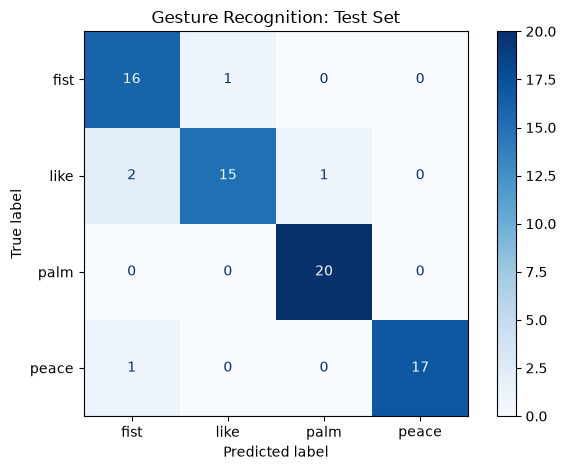

In [40]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    labels=model.classes_,
    cmap="Blues",
    values_format="d"
)

plt.title("Gesture Recognition: Test Set")
plt.tight_layout()
plt.show()

### 6.4 Quick Discussion 🔍

Look at your accuracy and confusion matrix.

1. Which gestures were recognised most accurately?
2. Which gestures were confused with one another?
3. Does high test accuracy guarantee good performance on a new person's hand?

**Remember:** Our test set contains unseen images, but may include people already represented in the training set.

**[INSTRUCTOR]**

Emphasise that high test accuracy does not guarantee reliable webcam predictions.

Our evaluation only measures classification on images where MediaPipe successfully detected a hand. It does not account for detection failures, and the test images may contain people also represented in training.

Live webcam testing will introduce additional differences in lighting, hand orientation, camera quality and background.

---

We have evaluated our classifier using landmark features extracted from HaGRID images.

But a real Computer Vision application starts with a **camera image**, not a feature vector.

Next, we'll connect the complete pipeline to our webcam:

**Webcam → MediaPipe → 21 Landmarks → 63 Normalised Features → Gesture Prediction**

Can our trained model recognise gestures in real time?

## 7. Test the Full CV Pipeline

So far, we have trained and evaluated our classifier using extracted landmark features.

Now, let's test the complete pipeline on new images and live webcam input.

**Our pipeline:**

Image → MediaPipe → 21 Landmarks → 63 Normalised Features → Gesture Prediction

### 7.1 Predict a Gesture from an Image

First, let's test our model on an image from the held-out test set.

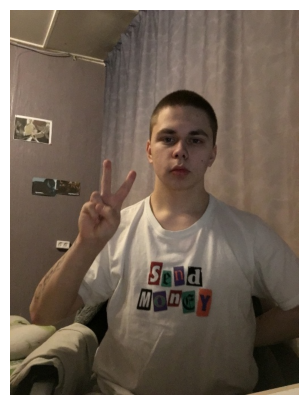

In [46]:
# Select an image from the held-out test set
UNSEEN_IMAGE_PATH = image_files[test_idx[0]]

unseen_image = cv2.imread(UNSEEN_IMAGE_PATH)

if unseen_image is None:
    raise FileNotFoundError(UNSEEN_IMAGE_PATH)

unseen_image_rgb = cv2.cvtColor(
    unseen_image, cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(5, 5))
plt.imshow(unseen_image_rgb)
plt.axis("off")
plt.show()

### 7.2 Detect Hand Landmarks

Use MediaPipe to detect the hand landmarks in the selected image.

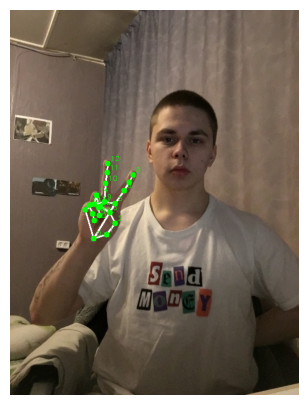

In [43]:
mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=unseen_image_rgb
)

result = landmarker.detect(mp_image)

if not result.hand_landmarks:
    raise ValueError("No hand detected.")

unseen_landmarks = result.hand_landmarks[0]

landmark_image = draw_hand_landmarks(
    unseen_image_rgb,
    unseen_landmarks
)

plt.figure(figsize=(5, 5))
plt.imshow(landmark_image)
plt.axis("off")
plt.show()

### 7.3 Predict the Gesture

Convert the landmarks into the **same 63 features used during training**, then make a prediction.

In [47]:
unseen_features = create_features(unseen_landmarks)

if unseen_features is None:
    raise ValueError("Invalid landmark features.")

X_unseen = unseen_features.reshape(1, -1)

prediction = model.predict(X_unseen)[0]
probabilities = model.predict_proba(X_unseen)[0]

print("Actual gesture:", y[test_idx[0]])
print("Predicted gesture:", prediction)
print("\nPrediction scores:")

for label, probability in zip(model.classes_, probabilities):
    print(f"{label:8s}: {probability:.1%}")

Actual gesture: peace
Predicted gesture: peace

Prediction scores:
fist    : 1.0%
like    : 0.0%
palm    : 1.0%
peace   : 98.0%


Feel free to try your own hand gesture picture as well!

### 7.4 Live Webcam Gesture Recognition 📷

Let's connect our trained classifier to a webcam and recognise gestures in real time.

For each frame, we will:

1. Detect hand landmarks using MediaPipe.
2. Extract the same 63 normalised features.
3. Predict the gesture using our trained classifier.
4. Display the prediction on the video.

**Try showing different gestures to your webcam!**

In [49]:
cap = cv2.VideoCapture(0)

if not cap.isOpened():
    cap.release()
    raise RuntimeError("Could not access webcam.")

print("Webcam started! Press 'q' to quit.")

try:
    while True:
        success, frame = cap.read()

        if not success:
            break

        # Convert BGR to RGB for MediaPipe
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=np.ascontiguousarray(frame_rgb)
        )

        # Detect hand landmarks
        result = landmarker.detect(mp_image)

        label = "No hand detected"
        confidence = None

        if result.hand_landmarks:
            landmarks = result.hand_landmarks[0]

            # Extract the same 63 features used during training
            features = create_features(landmarks)

            if features is not None:
                X_live = features.reshape(1, -1)

                # Predict using our trained Random Forest
                label = model.predict(X_live)[0]
                confidence = model.predict_proba(X_live).max()

            # Draw hand landmarks
            frame_rgb = draw_hand_landmarks(
                frame_rgb, landmarks
            )

        # Convert back to BGR for OpenCV display
        frame = cv2.cvtColor(frame_rgb, cv2.COLOR_RGB2BGR)

        # Display predicted gesture
        cv2.putText(
            frame,
            f"Gesture: {label}",
            (20, 40),
            cv2.FONT_HERSHEY_SIMPLEX,
            1,
            (0, 255, 0),
            2
        )

        # Display confidence score
        if confidence is not None:
            cv2.putText(
                frame,
                f"Confidence: {confidence:.1%}",
                (20, 80),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.8,
                (0, 255, 0),
                2
            )

        cv2.imshow("Live Gesture Recognition", frame)

        # Press Q to quit
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    cap.release()
    cv2.destroyAllWindows()

print("Webcam stopped.")

Webcam started! Press 'q' to quit.
Webcam stopped.


### 7.5 Quick Reflection 🔍

Try the four gestures: `fist`, `like`, `palm` and `peace`.

- Does the model recognise all four gestures correctly?
- What happens when you move your hand farther from the camera?
- Does changing your hand orientation affect the prediction?

**Remember:** Good test accuracy does not guarantee reliable real-world performance.